# 04. Descritiva

Fase 4. Descrição da base `data/03_processed/boletins.csv`, sem nenhuma
estimativa de elasticidade.

Quatro saídas:

- a) variação de preço de Inteira dentro de cada partida;
- b) composição e nível do público por regime e temporada;
- c) nível de preço de Inteira por clube mandante, temporada e estádio,
  nominal e real;
- d) relação bruta entre preço e público por setor e jogo.

Todo resultado traz o número de observações. Os gráficos são salvos em
`figuras/04_descritiva/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = RAIZ / "figuras" / "04_descritiva"
FIG.mkdir(parents=True, exist_ok=True)
REF = RAIZ / "referencias"

base = pd.read_csv(RAIZ / "data" / "03_processed" / "boletins.csv")

# Clube e estádio já vêm padronizados do lote (scripts/03_lote_boletins.py),
# pelos dicionários de referencias/. O texto do boletim fica em *_boletim.
for campo in ("mandante", "visitante", "estadio"):
    print(f"{campo}: {base[campo + '_boletim'].nunique()} nomes no boletim, "
          f"{base[campo].nunique()} padronizados, vazios: {base[campo].isna().sum()}")
base["clube_mandante"] = base.mandante
base["estadio_padrao"] = base.estadio

# Preço real em R$ da temporada 2026, com IPCA anual (dezembro a dezembro).
ipca = pd.read_csv(REF / "ipca.csv").set_index("ano").ipca_variacao_anual_pct
ULTIMA = base.ano.max()
fator = {t: float(np.prod([1 + ipca[y] / 100 for y in range(t, ULTIMA)])) for t in sorted(base.ano.unique())}
print("Fator de deflação para R$ de", ULTIMA, {t: round(f, 4) for t, f in fator.items()})
base["preco_real"] = base.preco * base.ano.map(fator)

REGIMES = ["mercado", "socio", "contrato", "promocional", "gratuidade", "nao_vendido"]
print(f"Linhas: {len(base):,}  Jogos: {base.groupby(['ano', 'jogo']).ngroups}")

mandante: 23 nomes no boletim, 22 padronizados, vazios: 0
visitante: 23 nomes no boletim, 22 padronizados, vazios: 0
estadio: 30 nomes no boletim, 26 padronizados, vazios: 0
Fator de deflação para R$ de 2026 {np.int64(2023): 1.1435, np.int64(2024): 1.093, np.int64(2025): 1.0426, np.int64(2026): 1.0}
Linhas: 12,241  Jogos: 388


## Subconjunto identificador

Linhas de regime mercado com `preco_regulado` falso. A definição é por
regime e preço regulado, não por categoria: as 45 linhas
`X - P.C.D. - Inteira` têm categoria Inteira, mas o preço delas não é a
Inteira do setor. Das 30 com Inteira comum do mesmo setor e jogo para
comparar, nenhuma custa a Inteira (23 custam exatamente metade). Ficam fora
por `preco_regulado`.

In [2]:
ident = base[(base.regime == "mercado") & ~base.preco_regulado].copy()
assert (ident.vendidos > 0).all() and (ident.categoria == "Inteira").all()
precos_por_jogo = ident.groupby(["ano", "jogo"]).preco.nunique()
jogos_com_variacao = precos_por_jogo[precos_por_jogo >= 2].index
ident["jogo_com_variacao"] = ident.set_index(["ano", "jogo"]).index.isin(jogos_com_variacao)

print(f"Observações: {len(ident):,}")
print(f"Jogos com Inteira de mercado: {ident.groupby(['ano', 'jogo']).ngroups}")
print(f"Jogos com ao menos dois preços distintos: {len(jogos_com_variacao)}")
print(f"Observações nesses jogos: {ident.jogo_com_variacao.sum():,}")
pcd = base[(base.subtipo == "P.C.D.") & (base.categoria == "Inteira")]
comum = (base[(base.categoria == "Inteira") & base.subtipo.isna() & (base.regime == "mercado")]
         .groupby(["ano", "jogo", "setor"]).preco.agg(["nunique", "first"]))
comp = pcd.merge(comum, left_on=["ano", "jogo", "setor"], right_index=True, how="inner")
comp = comp[comp["nunique"] == 1]
print(f"Linhas P.C.D. - Inteira: {len(pcd)}; com Inteira comum para comparar: {len(comp)}")
print("Razão P.C.D. / Inteira comum:", (comp.preco / comp["first"]).round(3).value_counts().to_dict())

Observações: 2,290
Jogos com Inteira de mercado: 387
Jogos com ao menos dois preços distintos: 314
Observações nesses jogos: 2,107
Linhas P.C.D. - Inteira: 45; com Inteira comum para comparar: 30
Razão P.C.D. / Inteira comum: {0.5: 23, 0.333: 3, 0.429: 2, 0.2: 1, 0.821: 1}


## a) Variação de preço intra-partida

Para cada jogo com ao menos dois preços distintos de Inteira de mercado, a
razão entre o maior e o menor preço. A razão é a mesma em preço nominal e
real, porque o deflator é constante dentro da partida.

count    314.000
mean       2.853
std        2.448
min        1.136
25%        1.667
50%        2.000
75%        2.625
90%        5.400
max       20.000
Name: razao, dtype: float64


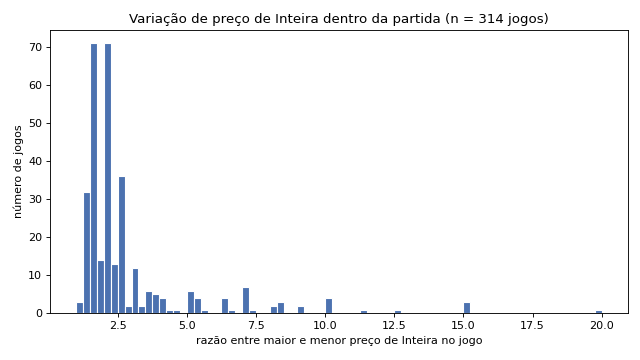

In [3]:
faixa = ident.groupby(["ano", "jogo"]).preco.agg(["min", "max", "nunique"])
faixa = faixa[faixa["nunique"] >= 2]
faixa["razao"] = faixa["max"] / faixa["min"]

resumo_a = faixa.razao.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(3)
print(resumo_a)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(faixa.razao, bins=np.arange(1, faixa.razao.max() + 0.25, 0.25), color="#4C72B0", edgecolor="white")
ax.set_xlabel("razão entre maior e menor preço de Inteira no jogo")
ax.set_ylabel("número de jogos")
ax.set_title(f"Variação de preço de Inteira dentro da partida (n = {len(faixa)} jogos)")
fig.tight_layout()
fig.savefig(FIG / "a_variacao_intrapartida.png", dpi=150)
plt.show()

## b) Composição e nível do público por regime e temporada

Dois painéis. À esquerda, a participação de cada regime no público da
temporada. À direita, ingressos por jogo, que não depende do número de
jogos da temporada (2026 tem 72 jogos, contra 103 a 109 nas outras).

Ingressos por regime e temporada
      mercado   socio  contrato  promocional  gratuidade  nao_vendido  revisão    total  jogos
ano                                                                                           
2023   672523  558677    116161            0       28195         5512      754  1381822    109
2024   628522  539554    132079            0       22322        21180     3627  1347284    104
2025   404609  630853    210546            0       20683        41063        0  1307754    103
2026   388946  285197     71016         3064       22880        13266        0   784369     72

Percentual por temporada
regime  mercado  socio  contrato  promocional  gratuidade  nao_vendido  revisão
ano                                                                            
2023       48.7   40.4       8.4          0.0         2.0          0.4      0.1
2024       46.7   40.0       9.8          0.0         1.7          1.6      0.3
2025       30.9   48.2      16.1          0.0      

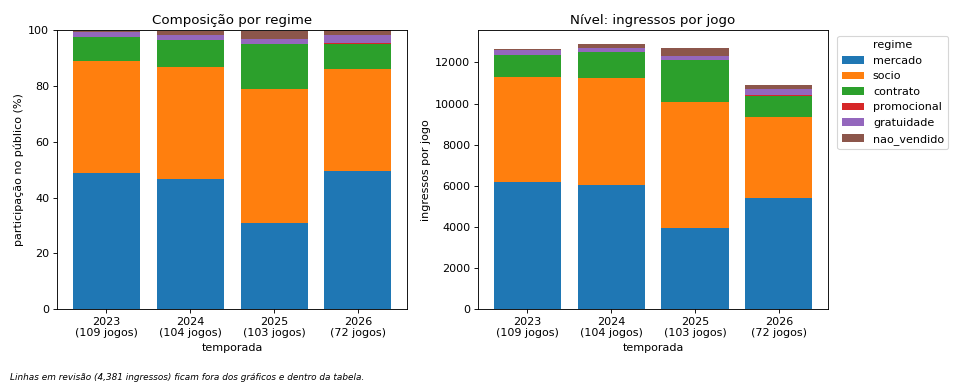

In [4]:
comp = (base[base.regime.isin(REGIMES)]
        .pivot_table(index="ano", columns="regime", values="vendidos", aggfunc="sum", fill_value=0)
        .reindex(columns=REGIMES, fill_value=0))
comp["revisão"] = base[base.regime.isna()].groupby("ano").vendidos.sum().reindex(comp.index, fill_value=0)
comp["total"] = comp.sum(axis=1)
jogos_ano = base.groupby("ano").jogo.nunique().rename("jogos")
tabela_b = comp.join(jogos_ano)
pct_b = (comp[REGIMES + ["revisão"]].div(comp["total"], axis=0) * 100).round(1)
por_jogo_b = comp[REGIMES + ["revisão", "total"]].div(jogos_ano, axis=0).round(0)
print("Ingressos por regime e temporada")
print(tabela_b.to_string())
print()
print("Percentual por temporada")
print(pct_b.to_string())
print()
print("Ingressos por jogo")
print(por_jogo_b.to_string())

rotulos = [f"{a}\n({j} jogos)" for a, j in jogos_ano.items()]
x = np.arange(len(comp))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
fundo1 = np.zeros(len(comp))
fundo2 = np.zeros(len(comp))
for regime in REGIMES:
    ax1.bar(x, pct_b[regime], bottom=fundo1, label=regime)
    fundo1 += pct_b[regime].values
    ax2.bar(x, por_jogo_b[regime], bottom=fundo2, label=regime)
    fundo2 += por_jogo_b[regime].values
for ax in (ax1, ax2):
    ax.set_xticks(x)
    ax.set_xticklabels(rotulos)
    ax.set_xlabel("temporada")
ax1.set_ylabel("participação no público (%)")
ax1.set_ylim(0, 100)
ax1.set_title("Composição por regime")
ax2.set_ylabel("ingressos por jogo")
ax2.set_title("Nível: ingressos por jogo")
ax2.legend(title="regime", bbox_to_anchor=(1.01, 1), loc="upper left")
fig.text(0.01, 0.01, f"Linhas em revisão ({int(comp['revisão'].sum()):,} ingressos) ficam fora dos gráficos e dentro da tabela.",
         fontsize=8, style="italic")
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(FIG / "b_composicao_regime.png", dpi=150)
plt.show()

## c) Nível de preço de Inteira por mandante, temporada e estádio

Observação: cada linha do subconjunto identificador (setor e subtipo de um
jogo), sem ponderação por ingressos. A tabela cobre os clubes com ao menos
8 jogos como mandante na base. O gráfico mostra só os **seis clubes com
mais jogos como mandante na base**, para ficar legível: um painel por
clube, um ponto por temporada e estádio.

Clubes fora (menos de 8 jogos como mandante): {'Capivariano': 4, 'Ferroviária': 6, 'Primavera': 4, 'São Bento': 6}
                                                           jogos  observacoes      q1  mediana     q3  mediana_real
clube_mandante       ano  estadio_padrao                                                                           
Botafogo             2023 Santa Cruz                           6           28  100.00   120.00  197.5        137.21
                     2024 Santa Cruz                           6           29  100.00   120.00  200.0        131.15
                     2025 Santa Cruz                           6           22  120.00   150.00  150.0        156.39
                     2026 Santa Cruz                           4           18   80.00   125.00  300.0        125.00
Corinthians          2023 Neo Química Arena                    7           66   65.00   130.00  220.0        148.65
                     2024 Neo Química Arena                    6         

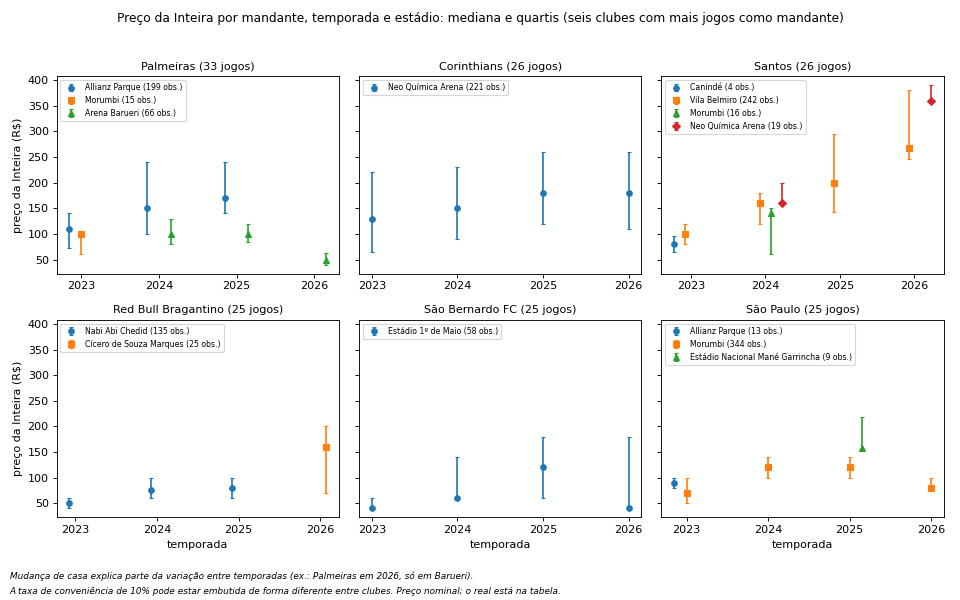

In [5]:
jogos_mandante = base.drop_duplicates(["ano", "jogo"]).groupby("clube_mandante").size()
elegiveis = jogos_mandante[jogos_mandante >= 8].index
fora = jogos_mandante[jogos_mandante < 8]
print("Clubes fora (menos de 8 jogos como mandante):", fora.to_dict())

c = ident[ident.clube_mandante.isin(elegiveis)]


def q1(s):
    return s.quantile(0.25)


def q3(s):
    return s.quantile(0.75)


tabela_c = (c.groupby(["clube_mandante", "ano", "estadio_padrao"])
            .agg(jogos=("jogo", "nunique"), observacoes=("preco", "size"),
                 q1=("preco", q1), mediana=("preco", "median"), q3=("preco", q3),
                 mediana_real=("preco_real", "median"))
            .round(2))
pd.set_option("display.width", 200)
print(tabela_c.to_string())

seis = jogos_mandante.sort_values(ascending=False, kind="stable").head(6)
print("Clubes no gráfico (mais jogos como mandante):", seis.to_dict())
anos = sorted(c.ano.unique())
marcadores = ["o", "s", "^", "D"]
fig, eixos = plt.subplots(2, 3, figsize=(12, 7.5), sharey=True)
for ax, clube in zip(eixos.flat, seis.index):
    t = tabela_c.loc[clube].reset_index()
    for k, (estadio, g) in enumerate(t.groupby("estadio_padrao", sort=False)):
        x = np.array([anos.index(a) for a in g.ano]) + (k - 0.5 * (t.estadio_padrao.nunique() - 1)) * 0.15
        ax.errorbar(x, g.mediana, yerr=[g.mediana - g.q1, g.q3 - g.mediana], fmt=marcadores[k % 4],
                    ms=5, capsize=2, label=f"{estadio} ({int(g.observacoes.sum())} obs.)")
    ax.set_title(f"{clube} ({seis[clube]} jogos)", fontsize=10)
    ax.set_xticks(range(len(anos)))
    ax.set_xticklabels(anos)
    ax.legend(fontsize=7, loc="upper left")
for ax in eixos[:, 0]:
    ax.set_ylabel("preço da Inteira (R$)")
for ax in eixos[-1, :]:
    ax.set_xlabel("temporada")
fig.suptitle("Preço da Inteira por mandante, temporada e estádio: mediana e quartis "
             "(seis clubes com mais jogos como mandante)", fontsize=11)
fig.text(0.01, 0.035, "Mudança de casa explica parte da variação entre temporadas (ex.: Palmeiras em 2026, só em Barueri).",
         fontsize=8, style="italic")
fig.text(0.01, 0.01, "A taxa de conveniência de 10% pode estar embutida de forma diferente entre clubes. Preço nominal; o real está na tabela.",
         fontsize=8, style="italic")
fig.tight_layout(rect=(0, 0.06, 1, 0.96))
fig.savefig(FIG / "c_preco_por_mandante.png", dpi=150)
plt.show()

**Estádio.** Mudança de casa explica parte da variação de preço entre
temporadas de um mesmo clube, não toda. A tabela acima, por mandante,
temporada e estádio, é a evidência. No Palmeiras, a troca do Allianz
(mediana de R$ 150 em 2024 e R$ 170 em 2025) por Barueri explica uma
parte da queda; a outra parte acontece dentro de Barueri, onde a mediana
foi R$ 100 em 2024 (5 jogos) e em 2025 (1 jogo) e R$ 50 em 2026 (7 jogos). Isso não afeta a Fase 5: o efeito fixo de partida
já absorve o estádio, porque cada partida acontece num estádio só.

**Preço real.** `preco_real` está em R$ da temporada 2026, deflacionado
pelo IPCA anual (`referencias/ipca.csv`). Dentro da partida nada muda: o
deflator é o mesmo para todas as linhas de um jogo, então razões de preço
dentro do jogo, e qualquer comparação com efeito fixo de partida, são
idênticas em nominal e real.

**Ressalva.** A taxa de conveniência de 10% pode estar embutida de forma
diferente entre clubes. Em parte dos boletins ela aparece como categoria
própria (Meia Social, Solidário); em outros pode estar dentro do preço da
Inteira. A comparação de nível entre clubes herda essa diferença.

In [6]:
palmeiras = tabela_c.loc["Palmeiras"]
print(palmeiras[["jogos", "observacoes", "mediana", "mediana_real"]].to_string())

                     jogos  observacoes  mediana  mediana_real
ano  estadio_padrao                                           
2023 Allianz Parque      8           86    110.0        125.78
     Morumbi             1           15    100.0        114.35
2024 Allianz Parque      4           41    150.0        163.94
     Arena Barueri       5           26    100.0        109.30
2025 Allianz Parque      7           72    170.0        177.24
     Arena Barueri       1            4    100.0        104.26
2026 Arena Barueri       7           36     50.0         50.00


In [7]:
tabela_c_ano = (c.groupby(["clube_mandante", "ano"])
                .agg(jogos=("jogo", "nunique"), observacoes=("preco", "size"),
                     mediana_nominal=("preco", "median"), mediana_real_2026=("preco_real", "median"))
                .round(2))
print(tabela_c_ano.to_string())

                           jogos  observacoes  mediana_nominal  mediana_real_2026
clube_mandante       ano                                                         
Botafogo             2023      6           28           120.00             137.21
                     2024      6           29           120.00             131.15
                     2025      6           22           150.00             156.39
                     2026      4           18           125.00             125.00
Corinthians          2023      7           66           130.00             148.65
                     2024      6           46           150.00             163.94
                     2025      9           76           180.00             187.67
                     2026      4           33           180.00             180.00
Grêmio Novorizontino 2024      6           24            40.00              43.72
                     2025      6           22            40.00              41.70
                

## Anomalia de composição em 2025

Em 2025, o público de mercado por jogo cai e o de sócio e contrato sobe,
em quase todos os mandantes ao mesmo tempo. A conta abaixo mede o
deslocamento e testa duas explicações: rótulo novo de sócio ou contrato, e
boletim menos detalhado. Nenhuma correção é aplicada.

In [8]:
jogos_ano = base.groupby("ano").jogo.nunique()
mercado_por_jogo = base[base.regime == "mercado"].groupby("ano").vendidos.sum() / jogos_ano
print("Ingressos de mercado por jogo:", mercado_por_jogo.round(0).to_dict())
deslocamento = (mercado_por_jogo[2024] - mercado_por_jogo[2025]) * jogos_ano[2025]
print(f"Deslocamento em 2025 ao ritmo de 2024: {deslocamento:,.0f} ingressos ({jogos_ano[2025]} jogos)")

por_cat = base.groupby(["ano", "categoria"]).vendidos.sum().unstack(0).fillna(0) / jogos_ano
por_cat_mercado = (base[base.regime == "mercado"].groupby(["ano", "categoria"]).vendidos.sum()
                   .unstack(0).fillna(0) / jogos_ano)
print("Variação por jogo 2024 para 2025, todas as linhas:")
for c in ["Sócio", "Carnê de Relacionamento", "Carnê Superficiária"]:
    print(f"  {c}: {por_cat.loc[c, 2025] - por_cat.loc[c, 2024]:+,.0f}")
print("Variação por jogo 2024 para 2025, regime mercado:")
for c in ["Meia", "Inteira"]:
    print(f"  {c}: {por_cat_mercado.loc[c, 2025] - por_cat_mercado.loc[c, 2024]:+,.0f}")

m = base[base.regime == "mercado"].groupby(["mandante", "ano"]).vendidos.sum()
jm = base.drop_duplicates(["ano", "jogo"]).groupby(["mandante", "ano"]).size()
pj = (m / jm).unstack()[[2024, 2025]].dropna()
pj["variacao_%"] = (pj[2025] / pj[2024] - 1) * 100
print("Mercado por jogo, por mandante (2024 e 2025):")
print(pj.round(0).sort_values("variacao_%").to_string())

anteriores = set(base[base.ano <= 2024].categoria_boletim.dropna())
novos = base[(base.ano == 2025) & base.regime.isin(["socio", "contrato"])
             & ~base.categoria_boletim.isin(anteriores)]
print(f"Rótulos de sócio e contrato novos em 2025: {novos.vendidos.sum():,} ingressos, "
      f"{sorted(novos.categoria_boletim.unique())}")
print("Linhas por boletim:", (base.groupby("ano").size() / jogos_ano).round(1).to_dict())

Ingressos de mercado por jogo: {2023: 6170.0, 2024: 6043.0, 2025: 3928.0, 2026: 5402.0}
Deslocamento em 2025 ao ritmo de 2024: 217,870 ingressos (103 jogos)
Variação por jogo 2024 para 2025, todas as linhas:
  Sócio: +839
  Carnê de Relacionamento: +635
  Carnê Superficiária: +292
Variação por jogo 2024 para 2025, regime mercado:
  Meia: -1,277
  Inteira: -754
Mercado por jogo, por mandante (2024 e 2025):
ano                      2024     2025  variacao_%
mandante                                          
Santos                 9995.0   2318.0       -77.0
Mirassol               3250.0    903.0       -72.0
Botafogo               3534.0   1261.0       -64.0
São Paulo             31138.0  13662.0       -56.0
Corinthians            3320.0   1599.0       -52.0
Palmeiras              8873.0   6289.0       -29.0
Inter Limeira          5532.0   4355.0       -21.0
Guarani                2549.0   2241.0       -12.0
São Bernardo FC        2822.0   2835.0         0.0
Red Bull Bragantino    1293.0 

## d) Relação bruta entre preço e público por setor e jogo

Observação: setor de um jogo com uma única Inteira de mercado no
subconjunto identificador. Eixo y: soma dos ingressos de regime mercado
vendidos no setor. Escala log nos dois eixos.

**Esta nuvem não é elasticidade.** A inclinação dela está contaminada por
endogeneidade: clube caro é clube grande. Preço e público sobem juntos
porque os dois dependem da demanda pelo clube e pelo jogo, não porque o
preço cause o público. Nenhuma inclinação é calculada aqui.

Setores-jogo com Inteira de mercado: 2,221
Com uma única Inteira (entram na nuvem): 2,212
Jogos: 387
       preco_inteira  ingressos_mercado
count         2212.0             2212.0
mean           122.3              907.5
std             88.8             1390.4
min             20.0                1.0
25%             60.0              100.0
50%            100.0              357.5
75%            150.0             1062.2
max            900.0             9679.0


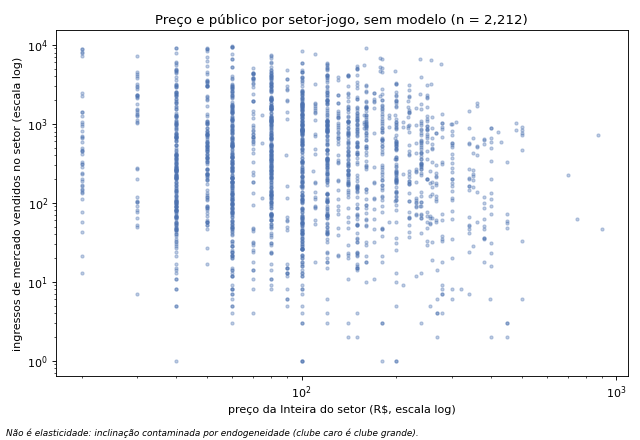

In [9]:
inteira_setor = ident.groupby(["ano", "jogo", "setor"]).preco.agg(["nunique", "first"])
unica = inteira_setor[inteira_setor["nunique"] == 1]["first"].rename("preco_inteira")
publico_setor = (base[base.regime == "mercado"].groupby(["ano", "jogo", "setor"]).vendidos.sum()
                 .rename("ingressos_mercado"))
d = pd.concat([unica, publico_setor], axis=1, join="inner")
print(f"Setores-jogo com Inteira de mercado: {len(inteira_setor):,}")
print(f"Com uma única Inteira (entram na nuvem): {len(d):,}")
print(f"Jogos: {d.reset_index().groupby(['ano', 'jogo']).ngroups}")
print(d.describe().round(1))

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(d.preco_inteira, d.ingressos_mercado, s=8, alpha=0.35, color="#4C72B0")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("preço da Inteira do setor (R$, escala log)")
ax.set_ylabel("ingressos de mercado vendidos no setor (escala log)")
ax.set_title(f"Preço e público por setor-jogo, sem modelo (n = {len(d):,})")
fig.text(0.01, 0.01, "Não é elasticidade: inclinação contaminada por endogeneidade (clube caro é clube grande).",
         fontsize=8, style="italic")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG / "d_preco_publico_setor.png", dpi=150)
plt.show()